In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/NYC311DATA_CLEANING.csv")

Mounted at /content/drive


In [3]:
df["created_date"] = pd.to_datetime(df["created_date"])
df["closed_date"] = pd.to_datetime(df["closed_date"])
df.shape

(99998, 17)

In [4]:
df.head()

,unique_key,created_date,agency,complaint_type,descriptor,borough,status,latitude,longitude,closed_date,bad_dates,bad_location,is_closed,resolution_hours,month,weekday,hour
0,70954964,2026-10-31 02:53:39,DSNY,Graffiti,Graffiti,MANHATTAN,OPEN,40.725465,-73.991879,NaT,False,False,False,NaN,10,Saturday,2
1,70944235,2026-10-31 01:36:03,NYPD,Noise - Street/Sidewalk,Loud Music/Party,BRONX,UNSPECIFIED,40.844059,-73.912748,NaT,False,False,False,NaN,10,Saturday,1
2,70952449,2026-10-31 01:35:32,NYPD,Noise - Residential,Loud Music/Party,BROOKLYN,IN PROGRESS,40.692542,-73.917887,NaT,False,False,False,NaN,10,Saturday,1
3,70947715,2026-10-31 01:35:23,NYPD,Noise - Residential,Loud Music/Party,MANHATTAN,IN PROGRESS,40.728187,-73.986723,NaT,False,False,False,NaN,10,Saturday,1
4,70945505,2026-10-31 01:35:08,NYPD,Illegal Parking,Posted Parking Sign Violation,MANHATTAN,IN PROGRESS,40.820977,-73.945379,NaT,False,False,False,NaN,10,Saturday,1


Keep only valid resolution hours

In [5]:
hours = df["resolution_hours"].dropna()

In [6]:
len(hours)

73065

Central tendency

In [7]:
print("Mean:  ", hours.mean())
print("Median:", hours.median())
print("Mode:  ", hours.mode()[0])

Mean:   18.17689686884585
Median: 2.5838888888888887
Mode:   0.0


In [8]:
#Spread
print("Min:     ", hours.min())
print("Max:     ", hours.max())
print("Range:   ", hours.max() - hours.min())
print("Q1 (25%):", hours.quantile(0.25))
print("Q3 (75%):", hours.quantile(0.75))
print("IQR:     ", hours.quantile(0.75) - hours.quantile(0.25))
print("Variance:", hours.var())
print("Std dev: ", hours.std())

Min:      0.0
Max:      200.01
Range:    200.01
Q1 (25%): 0.7483333333333333
Q3 (75%): 19.16111111111111
IQR:      18.412777777777777
Variance: 1053.9403076816645
Std dev:  32.464446825437584


0 means symmetric. Above 1 means strongly right-skewed (most cases are quick, a few take very long). Expect a large positive number.

In [9]:
#Skewness
print("Skewness:", hours.skew())

Skewness: 2.432919190566344


In [10]:
#Outliers using IQR
Q1 = hours.quantile(0.25)
Q3 = hours.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print("Lower limit:", lower)
print("Upper limit:", upper)

Lower limit: -26.87083333333333
Upper limit: 46.780277777777776


In [11]:
# The lower limit will probably be negative. Hours can’t be negative, so all the outliers are on the long side.
df["is_outlier"] = (df["resolution_hours"] < lower) | (df["resolution_hours"] > upper)
print("Outliers:", df["is_outlier"].sum())
print("Percent: ", round(df["is_outlier"].sum() / len(hours) * 100, 1), "%")

Outliers: 10916
Percent:  14.9 %


In [12]:
# Which complaints are the outliers?
# This is the “investigate, don’t delete” step. Long cases may be genuine; some types of work simply take weeks.
df[df["is_outlier"]]["complaint_type"].value_counts().head(10)

,count
complaint_type,
HEAT/HOT WATER,3869
Noise,633
Dirty Condition,589
UNSANITARY CONDITION,588
Street Condition,415
PAINT/PLASTER,388
Illegal Dumping,386
PLUMBING,338
Missed Collection,300


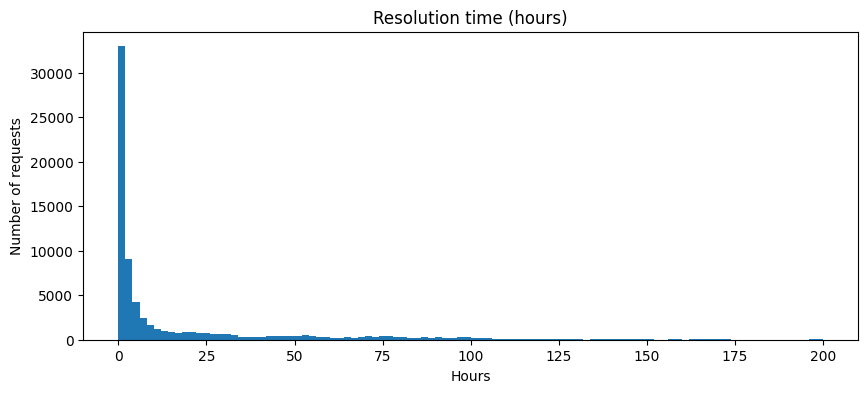

In [13]:
# Histogram
# 👉 You’ll see a tall bar near 0 and a long tail to the right. That’s the skew.
plt.figure(figsize=(10,4))
plt.hist(hours, bins=100)
plt.title("Resolution time (hours)")
plt.xlabel("Hours")
plt.ylabel("Number of requests")
plt.show()

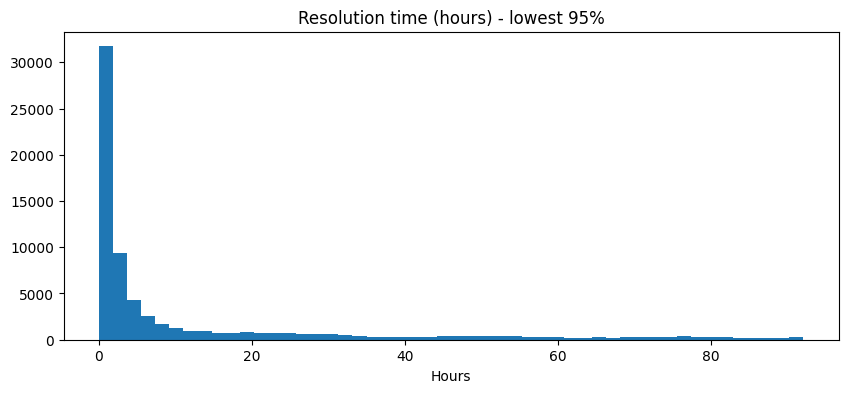

In [14]:
# A clearer version that zooms in on 95% of the data:
plt.figure(figsize=(10,4))
plt.hist(hours[hours < hours.quantile(0.95)], bins=50)
plt.title("Resolution time (hours) - lowest 95%")
plt.xlabel("Hours")
plt.show()

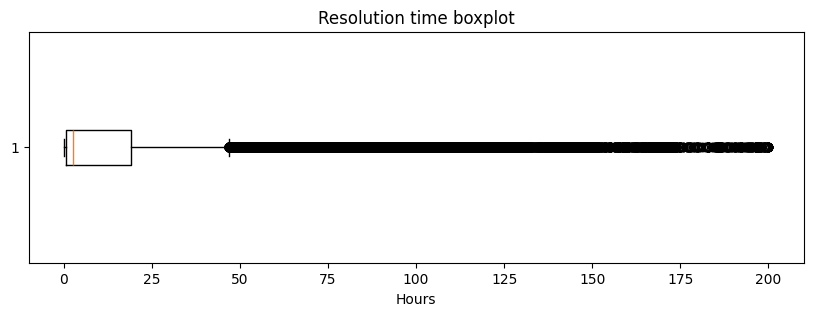

In [15]:
# Boxplot
plt.figure(figsize=(10,3))
plt.boxplot(hours, vert=False)
plt.title("Resolution time boxplot")
plt.xlabel("Hours")
plt.show()
# The dots on the right are the outliers.

In [16]:
# Median resolution is __ hours, while the mean is __ hours. The mean is higher because of a few very long cases.
# Skewness is __, so the distribution is strongly right-skewed.
# __ requests (__%) are IQR outliers above __ hours, mostly from __ complaint types.
# Outliers were flagged, not deleted, because long cases may be genuine.

In [17]:
df.to_csv("/content/drive/MyDrive/NYC311_EDA.csv", index=False)